[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/exercises/solutions/ex_00_data_exploration_solutions.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🛰️ Solutions: Tanager data exploration
### Space Academy 2026 · Hyperspectral course · Week 1 — Hyperspectral data access, visualization, and exploration (Practical)

Practise the basic moves of hyperspectral data handling on the coastal El Salvador scene from the quick-start notebook: choosing bands, reading spectra at map coordinates, judging how sensitive an index is to band choice, sampling large cubes efficiently, and masking before interpreting.

These exercises accompany the theme notebook [`00_EO_data_quickstart_notebook.ipynb`](../../../notebooks/00_EO_data_quickstart_notebook.ipynb). Run that notebook first
(or at least read it) — here we reuse its scene and indices, loaded with the course helper module `hsi_utils`.

> 🧑‍🏫 **Instructor version** — worked solutions with outputs. Students get the version without solutions in `exercises/`.

**What you will practise**
- Matching target wavelengths to real Tanager bands (centre and FWHM)
- Converting longitude/latitude to pixel positions and plotting pixel spectra
- Testing how sensitive an index is to the exact bands used
- Using strided reads for fast, representative statistics
- Masking before interpreting (water-only NDCI)

**Data**
- `20250223_165546_32_4001` — Usulután coast, El Salvador (mangroves, estuary, ocean, cropland)

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


## Setup

In [1]:
# hsi_utils.py lives in the course folder (../.. from here)
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parents[1]))

# On Google Colab: upload hsi_utils.py next to this notebook, change the line above to
# sys.path.insert(0, ".") and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio requests

import numpy as np
import matplotlib.pyplot as plt
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

Load the scene and the bands used in the theme notebook. `hu.get_scene()` finds the local HDF5 or downloads it (~1 GB) from Planet's STAC catalogue.

Scene      : 20250223_165546_32_4001  (Usulután, El Salvador)
File       : /home/course/notebooks/20250223_165546_32_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 655 rows × 785 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32616, 30 m pixels
No-data    : 28.2%   cloud flag: 0.0%   cirrus flag: 0.0%   usable: 71.8%


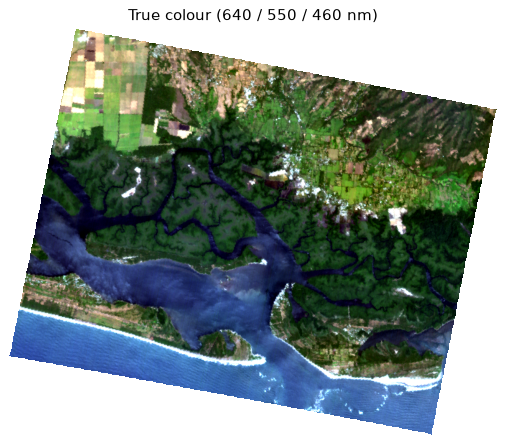

In [2]:
SCENE_ID = "20250223_165546_32_4001"   # Usulután coast, El Salvador (coastal-water-bodies)
scene = hu.get_scene(SCENE_ID)
print(scene.summary())

valid = scene.valid_mask()
# The four bands used for the indices in notebook 00
R560, R665, R708, R800 = (scene.read_band(w) for w in (560, 665, 708, 800))
R860 = scene.read_band(860)
NDWI = hu.nd(R560, R860)

fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(scene.rgb())
ax.set_title("True colour (640 / 550 / 460 nm)"); ax.axis("off")
plt.show()

## Exercise 1 — Which band is 'the red-edge band'?  ⭐

Notebook 00 asks for bands at 560, 665, 708 and 800 nm, but Tanager has no band *exactly* at those
wavelengths — it takes the closest one.

1. For each target wavelength (443, 560, 665, 708, 800, 1650 nm), print the band index, the actual centre
   wavelength, the difference from the target and the band's FWHM (full width at half maximum).
2. Sentinel-2 band B4 (red) is centred at 664.6 nm and is about 31 nm wide. How many Tanager bands fall
   inside B4 (centre ± FWHM/2)?

### Solution

In [3]:
print(f"{'target':>7} {'band':>5} {'centre':>8} {'Δ (nm)':>7} {'FWHM':>6}")
for target in (443, 560, 665, 708, 800, 1650):
    i = hu.band_index(scene.wavelengths, target)
    print(f"{target:7d} {i:5d} {scene.wavelengths[i]:8.2f} {scene.wavelengths[i] - target:7.2f} {scene.fwhm[i]:6.2f}")

c, w = hu.SENTINEL2_BANDS["B04"]
inside = (scene.wavelengths >= c - w / 2) & (scene.wavelengths <= c + w / 2)
print(f"\nTanager bands inside Sentinel-2 B4 ({c - w/2:.0f}–{c + w/2:.0f} nm): {inside.sum()}")
print(np.round(scene.wavelengths[inside], 1))

 target  band   centre  Δ (nm)   FWHM
    443    13   441.10   -1.90   5.77
    560    37   560.83    0.83   6.30
    665    58   665.87    0.87   6.59
    708    66   705.92   -2.08   6.66
    800    85   801.12    1.12   6.77
   1650   254  1647.66   -2.34   5.93

Tanager bands inside Sentinel-2 B4 (649–680 nm): 6
[650.8 655.9 660.9 665.9 670.9 675.9]


**What you should see:** every target is matched within ±2.5 nm (the band spacing is ~5 nm) and the
bands are only ~5–7 nm wide. Six Tanager bands fit inside the single Sentinel-2 red band — that is what
"hyperspectral" buys you: a narrow feature such as the chlorophyll absorption minimum near 670 nm is
sampled several times instead of being averaged away.

## Exercise 2 — A pixel spectrum from a map coordinate  ⭐

Field teams and partners give you **longitude/latitude**, not row/column. Plot the spectra of these three
points on one figure:

| Point | Longitude | Latitude |
|---|---|---|
| Mangrove forest | −88.4404 | 13.2276 |
| Turbid estuary water | −88.4427 | 13.1631 |
| Sugar-cane field | −88.5104 | 13.2739 |

Use `hu.plot_spectrum` so the lines break at the removed water-vapour bands. Then describe in one sentence
per spectrum *why* it has the shape it has.

### Solution

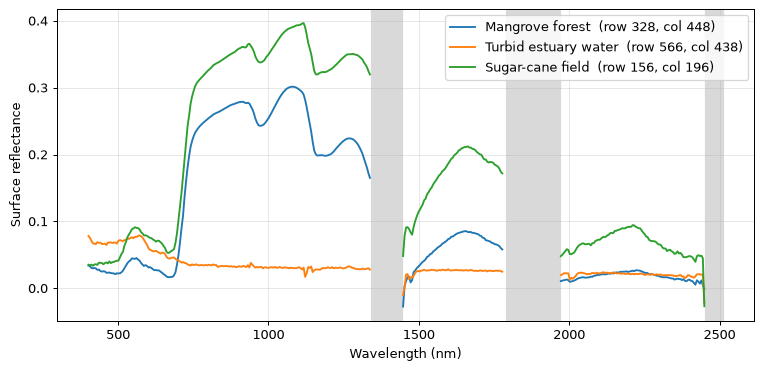

In [4]:
points = {"Mangrove forest": (-88.4404, 13.2276),
          "Turbid estuary water": (-88.4427, 13.1631),
          "Sugar-cane field": (-88.5104, 13.2739)}

fig, ax = plt.subplots(figsize=(10, 4.5))
hu.shade_bad_regions(ax)
for name, (lon, lat) in points.items():
    row, col = scene.lonlat_to_rowcol(lon, lat)
    spec, wl = scene.read_pixel(int(row[0]), int(col[0]))
    hu.plot_spectrum(ax, wl, spec, label=f"{name}  (row {row[0]}, col {col[0]})")
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Surface reflectance")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Interpretation**
- **Mangrove:** low visible reflectance with a small green peak (chlorophyll absorbs blue and red), a steep
  *red edge* near 700–750 nm, a high NIR plateau from leaf structure, and SWIR dips at ~1450/1950 nm caused
  by leaf water.
- **Sugar cane:** the same vegetation shape but brighter in the NIR and SWIR (a different canopy structure and
  water content) — the kind of difference that lets hyperspectral data separate crop and forest types.
- **Turbid water:** brightest in the green–red (suspended sediment scatters light), then close to zero beyond
  ~900 nm because water absorbs NIR and SWIR strongly.

## Exercise 3 — How much does the band choice change NDVI?  ⭐⭐

Notebook 00 computes NDVI with NIR = 800 nm and red = 665 nm. Other notebooks use NIR = 860 nm.
Compute both versions over the scene and quantify the difference:

1. Mean and 95th percentile of |NDVI₈₀₀ − NDVI₈₆₀| over valid pixels.
2. The same statistic separately for vegetation (NDVI₈₀₀ > 0.5) and water (NDWI > 0.1).
3. A scatter plot (or 2-D histogram) of one version against the other.

When does the band choice matter, and when doesn't it?

### Solution

all valid                    n= 371369  mean |Δ| = 0.019   95th pct = 0.046
vegetation (NDVI₈₀₀ > 0.5)   n= 220819  mean |Δ| = 0.014   95th pct = 0.031
water (NDWI > 0.1)           n= 102061  mean |Δ| = 0.023   95th pct = 0.060


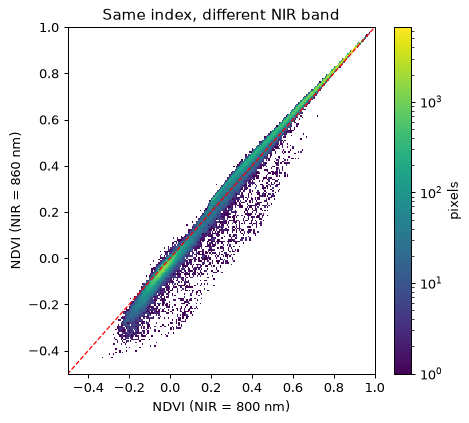

In [5]:
NDVI_800 = hu.nd(R800, R665)
NDVI_860 = hu.nd(R860, R665)
diff = np.abs(NDVI_800 - NDVI_860)

groups = {"all valid": valid, "vegetation (NDVI₈₀₀ > 0.5)": valid & (NDVI_800 > 0.5), "water (NDWI > 0.1)": valid & (NDWI > 0.1)}
for name, m in groups.items():
    d = diff[m & np.isfinite(diff)]
    print(f"{name:28s} n={d.size:7d}  mean |Δ| = {d.mean():.3f}   95th pct = {np.percentile(d, 95):.3f}")

ok = np.isfinite(NDVI_800) & np.isfinite(NDVI_860)
plt.figure(figsize=(5.5, 5))
plt.hist2d(NDVI_800[ok], NDVI_860[ok], bins=200, cmin=1, cmap="viridis", norm="log")
plt.plot([-1, 1], [-1, 1], "r--", lw=1)
plt.xlim(-0.5, 1); plt.ylim(-0.5, 1)
plt.xlabel("NDVI (NIR = 800 nm)"); plt.ylabel("NDVI (NIR = 860 nm)")
plt.colorbar(label="pixels"); plt.title("Same index, different NIR band")
plt.show()

**Interpretation:** for dense vegetation the NIR plateau is almost flat between 800 and 860 nm, so both
versions agree to within about 0.01. Over water the NIR signal is tiny and noisy, so the ratio is unstable and
the choice of band matters much more, in relative terms. **Lesson:** always report the exact wavelengths you
used, and don't compare index thresholds between notebooks, papers or sensors unless the band definitions match.

## Exercise 4 — Strided reads: fast previews that are good enough  ⭐⭐

Notebook 00 computes the mean spectrum with `stride = 8` (every 8th row and column, i.e. 1/64 of the pixels).
Is that accurate enough?

1. Compute the scene-mean spectrum (valid pixels, good bands) with strides 16, 8 and 4, and time each read.
2. Use stride 2 as the reference and report, for each stride, the root-mean-square difference to the reference
   in reflectance units and in % of the mean reflectance.

### Solution

stride  pixels used  read time   RMS diff  % of mean
    16        0.39%       2.3s    0.00078      0.66%
     8        1.56%       2.3s    0.00048      0.41%
     4        6.25%       2.6s    0.00012      0.10%
     2       25.00%       3.6s    0.00000      0.00%


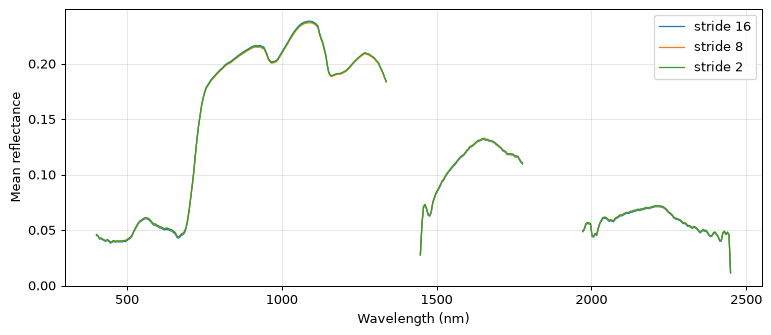

In [6]:
import time

means, times = {}, {}
for s in (16, 8, 4, 2):
    t0 = time.perf_counter()
    cube, wl = scene.read_cube(stride=s)
    means[s] = np.nanmean(cube, axis=(1, 2))
    times[s] = time.perf_counter() - t0
    del cube

ref = means[2]
print(f"{'stride':>6} {'pixels used':>12} {'read time':>10} {'RMS diff':>10} {'% of mean':>10}")
for s in (16, 8, 4, 2):
    rms = np.sqrt(np.nanmean((means[s] - ref) ** 2))
    print(f"{s:6d} {1 / s**2:12.2%} {times[s]:9.1f}s {rms:10.5f} {rms / np.nanmean(ref):10.2%}")

fig, ax = plt.subplots(figsize=(10, 4))
for s in (16, 8, 2):
    hu.plot_spectrum(ax, wl, means[s], label=f"stride {s}", lw=1)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Mean reflectance"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Interpretation:** the scene-mean spectrum from 1/64 of the pixels differs from the stride-2 reference by
well under 1% — the lines are indistinguishable. Reading time, on the other hand, barely drops, because
HDF5 decompresses whole chunks even when you only keep every n-th pixel. Striding is great for **statistics
and previews**, but it throws away the spatial detail you need for mapping small objects (a 30 m pier
disappears at stride 8 = 240 m).

## Exercise 5 — Chlorophyll (NDCI) over water only  ⭐⭐⭐

NDCI = (R₇₀₈ − R₆₆₅) / (R₇₀₈ + R₆₆₅) is a **water** index (Mishra & Mishra, 2012). Over land it simply lights
up vegetation, which makes the colour scale in notebook 00 useless for water.

1. Build a water mask (NDWI > 0.1 and valid) and compute NDCI only for water pixels.
2. Map it with a colour scale chosen from the water pixels' own 2nd–98th percentiles.
3. Compare the NDCI distribution of the **estuary / lagoon** with the **open ocean**. The open ocean lies
   south of the barrier beach, which runs roughly along the pixel line `row = 460 + 0.21 × col`
   (water pixels below that line = ocean).
4. Is the higher NDCI in one of them necessarily more chlorophyll? What else raises R₇₀₈ relative to R₆₆₅?

### Solution

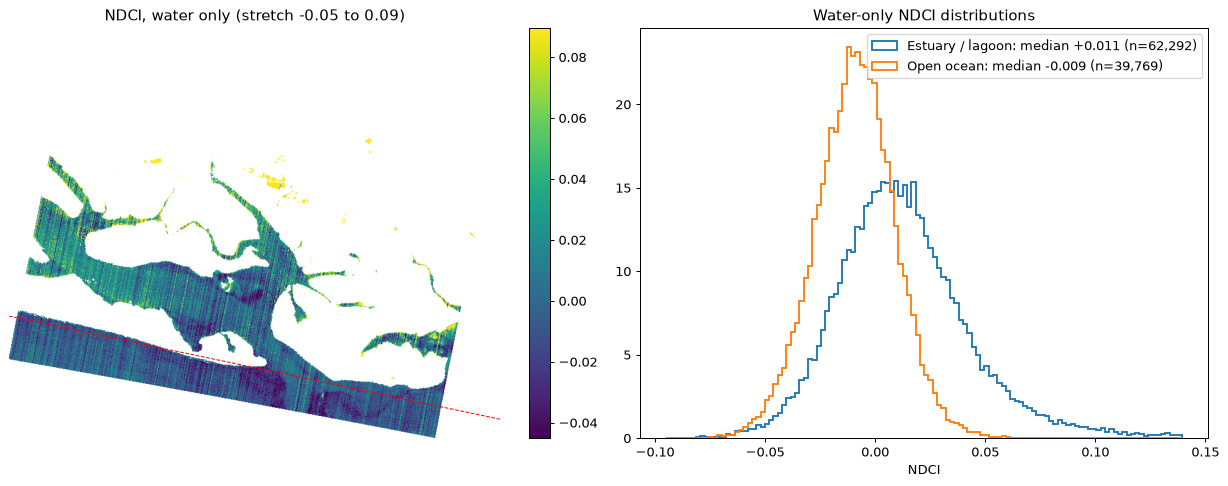

Correlation of NDCI with R665 (sediment proxy) over water: -0.22


In [7]:
water = valid & (NDWI > 0.1)
NDCI = hu.nd(R708, R665)
NDCI_water = np.where(water, NDCI, np.nan)
lo, hi = np.nanpercentile(NDCI_water, [2, 98])

rows, cols = np.indices(water.shape)
ocean = water & (rows > 460 + 0.21 * cols)   # south of the barrier beach
lagoon = water & ~ocean

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
im = axes[0].imshow(NDCI_water, cmap="viridis", vmin=lo, vmax=hi)
axes[0].set_title(f"NDCI, water only (stretch {lo:.2f} to {hi:.2f})"); axes[0].axis("off")
axes[0].plot(np.arange(water.shape[1]), 460 + 0.21 * np.arange(water.shape[1]), "r--", lw=0.8)
axes[0].set_xlim(0, water.shape[1]); axes[0].set_ylim(water.shape[0], 0)
plt.colorbar(im, ax=axes[0], fraction=0.046)
for name, m in (("Estuary / lagoon", lagoon), ("Open ocean", ocean)):
    v = NDCI[m]
    axes[1].hist(v, bins=120, range=(lo - 0.05, hi + 0.05), histtype="step", density=True, lw=1.5,
                 label=f"{name}: median {np.median(v):+.3f} (n={v.size:,})")
axes[1].set_xlabel("NDCI"); axes[1].legend(); axes[1].set_title("Water-only NDCI distributions")
plt.tight_layout(); plt.show()

R665_w = R665[water]
print("Correlation of NDCI with R665 (sediment proxy) over water:", round(np.corrcoef(NDCI[water], R665_w)[0, 1], 2))

**Interpretation:** restricted to water, NDCI spans only a few hundredths, so a colour scale fitted to the land
(−0.2 to 0.4 in notebook 00) hides all structure. Compare the medians of the two groups printed in the legend.

A higher NDCI is **not automatically more chlorophyll**: in shallow or turbid water, sediment, the seafloor and
floating or submerged vegetation also raise the red-edge reflectance, and the correlation with R₆₆₅ printed above
shows how strongly NDCI co-varies with brightness in this scene. Converting NDCI into chlorophyll-a (mg m⁻³)
needs a calibration against **in-situ samples** — which is exactly the kind of validation your project must plan for.

## Exercise 6 — Reflection — what is 'the scene mean' actually averaging?  ⭐

Answer in a few sentences (markdown cell):

1. What fraction of the grid is usable (valid) and why is it not 100% even though the cloud cover is 0%?
2. The theme notebook plots **one mean spectrum for the whole scene**. Roughly what share of the valid
   pixels is water, and how does that shape the mean spectrum? When is a scene-mean spectrum misleading?

### Solution

In [8]:
m = scene.masks()
print(f"no-data (outside the rotated footprint): {m['nodata'].mean():.1%}")
print(f"usable pixels:                           {valid.mean():.1%}")
print(f"water share of the usable pixels:        {(valid & (NDWI > 0.1)).sum() / valid.sum():.1%}")

no-data (outside the rotated footprint): 27.8%
usable pixels:                           72.2%
water share of the usable pixels:        27.5%


**Model answer**
1. About 28% of the rectangular HDF5 grid lies outside the tilted image footprint and is flagged *no-data*;
   clouds play no role in this scene.
2. Roughly a quarter of the usable pixels are water. The mean spectrum is therefore a **mixture** of vegetation
   and water: its NIR plateau is lower than any vegetation pixel's and its SWIR is darker than any land
   pixel's. A scene mean describes no real surface — it is useful as a quick quality check (does the spectrum
   look physically plausible?), but analysis should always be done per class or per region of interest.

## Key takeaways

- Tanager's ~5 nm bands sample narrow features that a multispectral band averages away.
- Always state the exact wavelengths of an index — thresholds are not transferable otherwise.
- Strided reads give representative statistics quickly, but not spatial detail.
- Mask first (water, vegetation, valid pixels), then interpret; a scene mean mixes everything.

---

> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC